In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)


32033

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [28]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22767, 3]) torch.Size([22767])
torch.Size([22799, 3]) torch.Size([22799])


In [111]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)        #* 0.2
# b1 = torch.randn(n_hidden,                        generator=g) * 0.02
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01
b2 = torch.randn(vocab_size,                      generator=g) * 0

# BatchNorm parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]        # b1 is bias which we don't need  as batch-norm has it's own bias
# parameters = [C, W1,b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [104]:
hpreact.mean(0, keepdim = True).shape

torch.Size([1, 200])

In [104]:
hpreact.std(0, keepdim = True).shape

torch.Size([1, 200])

In [112]:
# # same optimization as last time
# max_steps = 200000
# batch_size = 32
# lossi = []

# for i in range(max_steps):
  
#   # minibatch construct
#   ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
#   Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
#   # forward pass
#   emb = C[Xb] # embed the characters into vectors
#   embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
#   hpreact = embcat @ W1 + #b1          # Linear layer pre-activation

#   bnmeani = hpreact.mean(0,keepdim= True)
#   bnstdi = hpreact.std(0, keepdim = True)
#   hpreact= bngain * (hpreact- bnmeani)/ bnstdi  + bnbias   # batch normalization layer

#   with torch.no_grad():
#       bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
#       bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    
#   h = torch.tanh(hpreact)             # hidden layer   
#   logits = h @ W2 + b2                # output layer
#   loss = F.cross_entropy(logits, Yb)     # loss function
  
#   # backward pass
#   for p in parameters:
#     p.grad = None
#   loss.backward()
  
#   # update
#   lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
#   for p in parameters:
#     p.data += -lr * p.grad

#   # track stats
#   if i % 10000 == 0: # print every once in a while
#     print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
#   lossi.append(loss.log10().item())
#   # break

# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 #+ b1 # hidden layer pre-activation
  # BatchNorm layer
  # -------------------------------------------------------------
  bnmeani = hpreact.mean(0, keepdim=True)
  bnstdi = hpreact.std(0, keepdim=True)
  hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
  with torch.no_grad():
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
  # -------------------------------------------------------------
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3014
  10000/ 200000: 2.4789
  20000/ 200000: 2.3364
  30000/ 200000: 2.1072
  40000/ 200000: 2.0523
  50000/ 200000: 2.4329
  60000/ 200000: 2.2905
  70000/ 200000: 2.0826
  80000/ 200000: 2.0123
  90000/ 200000: 2.0183
 100000/ 200000: 2.4473
 110000/ 200000: 2.0486
 120000/ 200000: 2.1925
 130000/ 200000: 2.3584
 140000/ 200000: 2.2693
 150000/ 200000: 2.3672
 160000/ 200000: 2.0888
 170000/ 200000: 2.0872
 180000/ 200000: 2.4111
 190000/ 200000: 1.8808


tensor(0.0015) tensor(1.0080)
tensor(0.0083) tensor(3.1193)


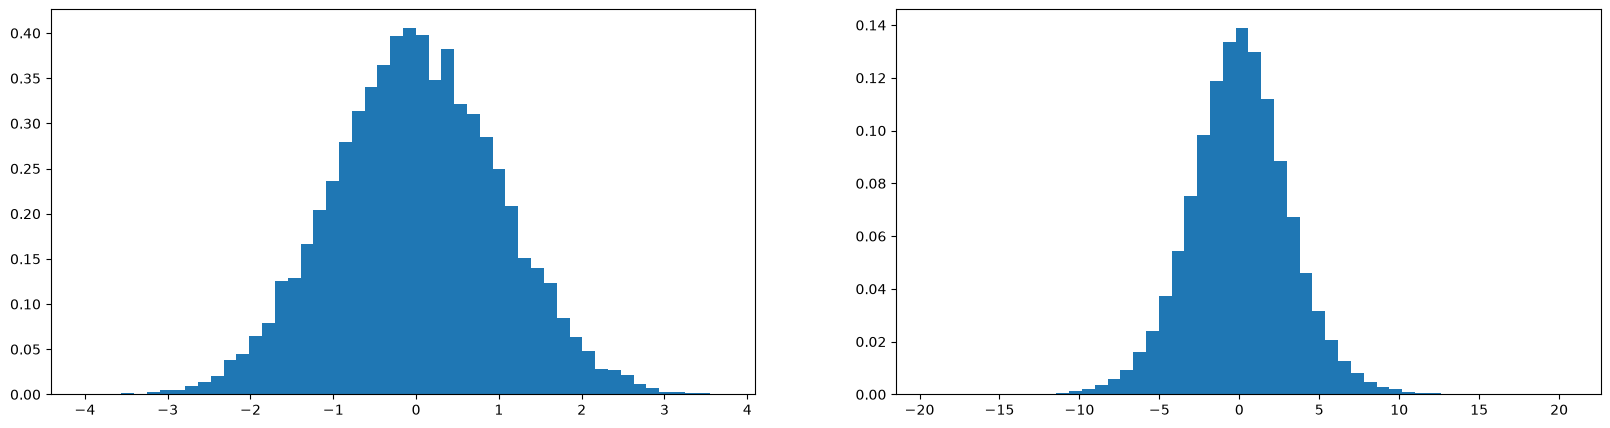

In [99]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200)
y = x @ w
print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize = (20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density = True);
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density = True);

In [91]:
# actual starting loss should be this cause there are total 27 things in it so prob = 1/27 of each minimum

print(-torch.tensor(1/27.0).log())   
logits[0]

tensor(3.2958)


tensor([-5.0909,  1.7937,  0.6921,  0.7316,  0.8985,  0.7728, -0.3980, -0.0153,
         0.1053, -0.2558,  1.2929,  1.4453,  0.9184,  1.3456,  0.6477, -0.4757,
        -0.2219, -2.0439,  0.8745,  1.1770,  0.7116, -2.2278, -0.6416, -0.6510,
        -1.7455, -0.4464,  0.3923], grad_fn=<SelectBackward0>)

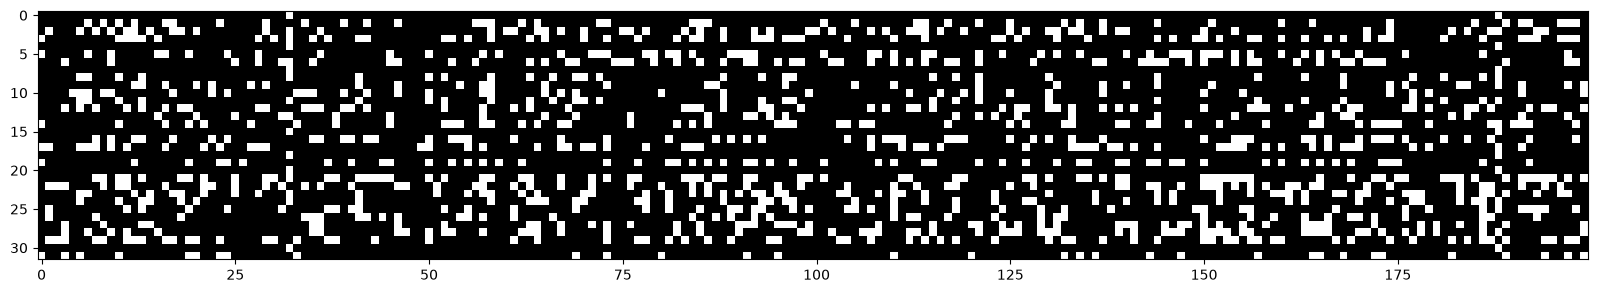

In [92]:
plt.figure(figsize = (20, 10))
plt.imshow(h.abs() > 0.99, cmap = 'gray', interpolation = 'nearest')   # it's a boolean tensor so true = white , false = black

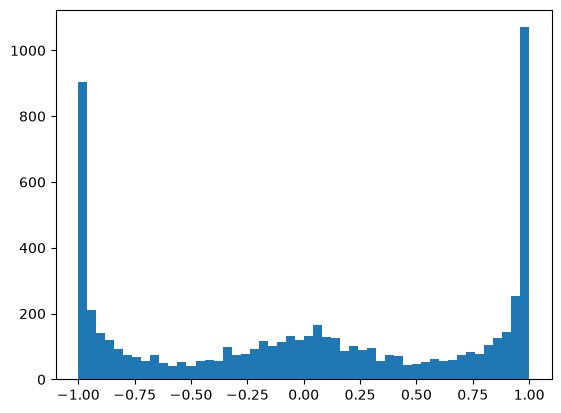

In [93]:
plt.hist(h.view(-1).tolist(), 50);

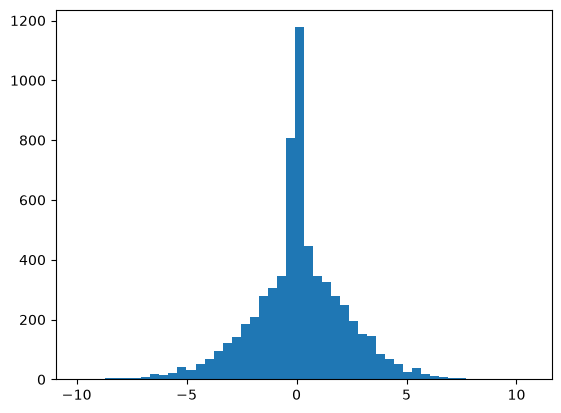

In [94]:
plt.hist(hpreact.view(-1).tolist(), 50);

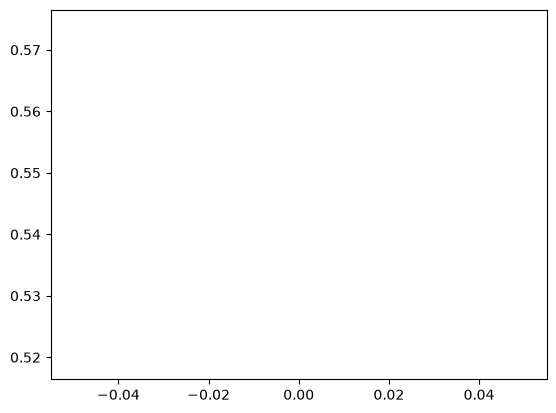

In [65]:
plt.plot(lossi)

In [113]:
# calibrate batch norm at end of training

with torch.no_grad():
    # pass the training set through
    emb = C[Xtr]
    embrat = emb.view(emb.shape[0],-1)
    hpreact = embcat @ W1 + b1
    # measure the mean / std over the entire training set
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim = True)
    

In [118]:
bnstd

tensor([[2.2270, 1.7502, 1.6966, 2.4745, 1.6342, 1.7745, 2.2026, 2.5385, 2.6801,
         1.9109, 2.5542, 2.1951, 1.9881, 2.0562, 1.5996, 2.9921, 2.2193, 1.7424,
         1.9329, 2.5031, 2.4945, 2.0480, 1.7863, 1.9708, 1.9829, 2.0588, 1.9325,
         2.0568, 2.2910, 2.4431, 1.3623, 1.9458, 2.5263, 1.6286, 1.5263, 1.8413,
         2.7212, 1.6541, 1.8767, 1.5214, 2.2238, 2.6162, 2.0887, 1.6853, 2.1910,
         2.4423, 1.4168, 2.0843, 2.2383, 2.1047, 2.1444, 1.7441, 2.1115, 1.7700,
         2.1947, 2.4551, 1.3580, 2.0611, 3.2239, 1.8886, 2.1794, 1.7164, 1.8726,
         2.0723, 2.5305, 1.8999, 2.3299, 2.8214, 1.4190, 2.1226, 1.3180, 2.0841,
         2.4658, 1.7054, 2.2102, 1.6498, 2.1937, 2.1486, 1.9665, 1.8822, 1.4557,
         1.4741, 2.7994, 2.0002, 2.1802, 2.2707, 2.4720, 2.0997, 2.5739, 2.7053,
         2.1786, 1.9972, 2.1252, 1.7521, 2.1339, 2.2503, 1.9843, 1.8754, 2.1052,
         2.0736, 1.9294, 2.1344, 2.0285, 1.6507, 1.6714, 2.1471, 1.4674, 2.4267,
         2.1238, 1.5386, 1.7

In [119]:
bnstd_running

tensor([[2.2030, 2.0195, 2.0998, 2.1248, 2.0291, 2.2906, 2.2242, 2.1432, 2.2934,
         2.0363, 2.3802, 2.0948, 2.2339, 1.8748, 1.9036, 2.8334, 2.2508, 1.9044,
         2.1870, 2.5079, 2.3591, 2.2196, 1.9478, 2.2009, 2.1996, 2.1080, 2.0470,
         2.4871, 2.5198, 2.4299, 1.6562, 2.0355, 2.3704, 2.0184, 1.9683, 1.8921,
         2.5442, 2.0547, 2.1625, 1.7325, 2.0561, 1.9847, 2.5524, 1.8721, 2.3298,
         2.2723, 2.1270, 2.6336, 2.2524, 2.2493, 1.9543, 1.8907, 2.0204, 1.8932,
         2.1920, 2.2426, 2.0363, 2.1669, 2.8736, 2.1454, 2.1583, 2.0002, 1.9726,
         2.2755, 2.3424, 2.1529, 2.0752, 2.3844, 1.8329, 2.0456, 2.0832, 1.9610,
         2.1782, 1.9896, 2.0066, 1.7171, 2.4608, 2.3095, 2.0104, 2.2371, 2.0314,
         1.9588, 2.0787, 2.3496, 2.1894, 2.2924, 2.1731, 2.3748, 2.4559, 2.7414,
         2.0677, 1.8271, 2.0672, 1.8647, 1.8210, 2.1454, 2.0712, 1.8953, 2.1554,
         2.2833, 2.0686, 2.1829, 2.1135, 2.2232, 1.9766, 2.2291, 1.8600, 2.1242,
         1.8527, 2.0952, 2.1

In [120]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1          # Linear layer pre-activation  
  # hpreact= bngain * (hpreact- hpreact.mean(0,keepdim= True))/ hpreact.std(0, keepdim = True) + bnbias   # batch normalization layer
  hpreact= bngain * (hpreact- bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 3.091339349746704
val 3.1291494369506836


In [33]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

carmaizabelle.
khi.
milia.
atl.
salaysie.
mahnie.
delynn.
jareei.
ner.
kia.
chaiivia.
leigh.
ham.
join.
quint.
sulenes.
jamilio.
jermaijarynix.
kaeunivrah.
emmedi.


In [ ]:
# SUMMARY + PYTORCHIFYING -----------

In [156]:
# Let's train a deeper network
# The classes we create here are the same API as nn.Module in PyTorch

class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
    self.bias = torch.zeros(fan_out) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)
  
  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647) # for reproducibility

C = torch.randn((vocab_size, n_embd),            generator=g)
layers = [
  Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size, bias=False), BatchNorm1d(vocab_size),
]
layers = [
  Linear(n_embd * block_size, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size),
]

with torch.no_grad():
  # last layer: make less confident
  # layers[-1].gamma *= 0.1
  layers[-1].weight *= 0.1
  # all other layers: apply gain
  for layer in layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

46497


In [157]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function
  
  # backward pass
  for layer in layers:
    layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  # lr = 0.01  
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
    
  with torch.no_grad():
    ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

  if i >= 1000:
    break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 3.3008


layer 1 (      Tanh): mean +0.01, std 0.75, saturated: 20.47%
layer 3 (      Tanh): mean +0.04, std 0.71, saturated: 12.12%
layer 5 (      Tanh): mean -0.02, std 0.72, saturated: 10.12%
layer 7 (      Tanh): mean +0.06, std 0.71, saturated: 10.78%
layer 9 (      Tanh): mean -0.01, std 0.72, saturated: 10.81%


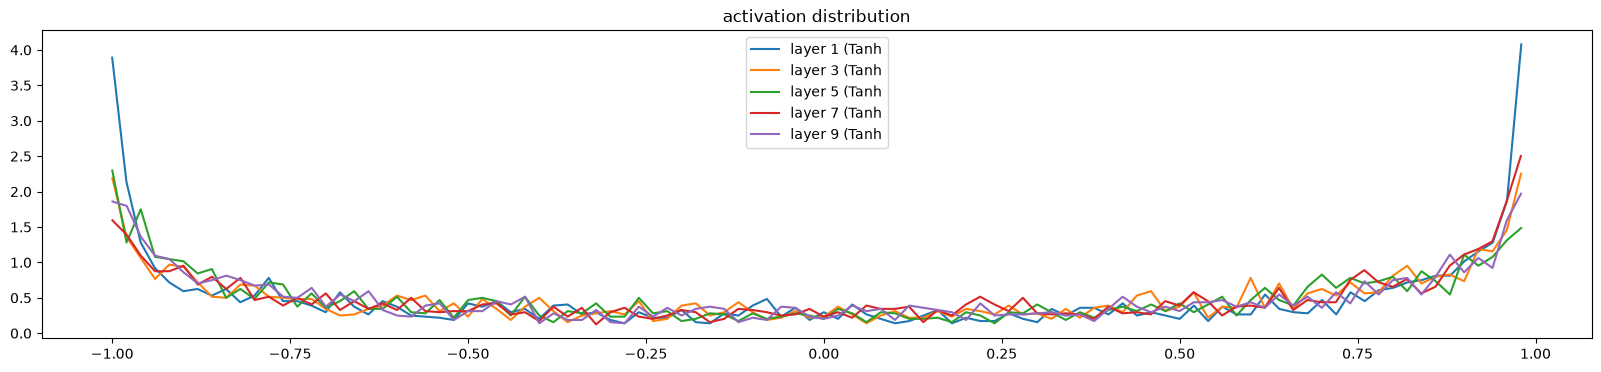

In [158]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution');

weight      (27,) | mean -0.000070 | std 3.250367e-03 | grad:data ratio 1.705478e-02
weight      (27,) | mean -0.000032 | std 3.063399e-03 | grad:data ratio 1.607375e-02
weight      (27,) | mean +0.000062 | std 2.851868e-03 | grad:data ratio 1.496384e-02
weight      (27,) | mean +0.000006 | std 2.577965e-03 | grad:data ratio 1.352666e-02
weight      (27,) | mean -0.000024 | std 2.177679e-03 | grad:data ratio 1.142635e-02


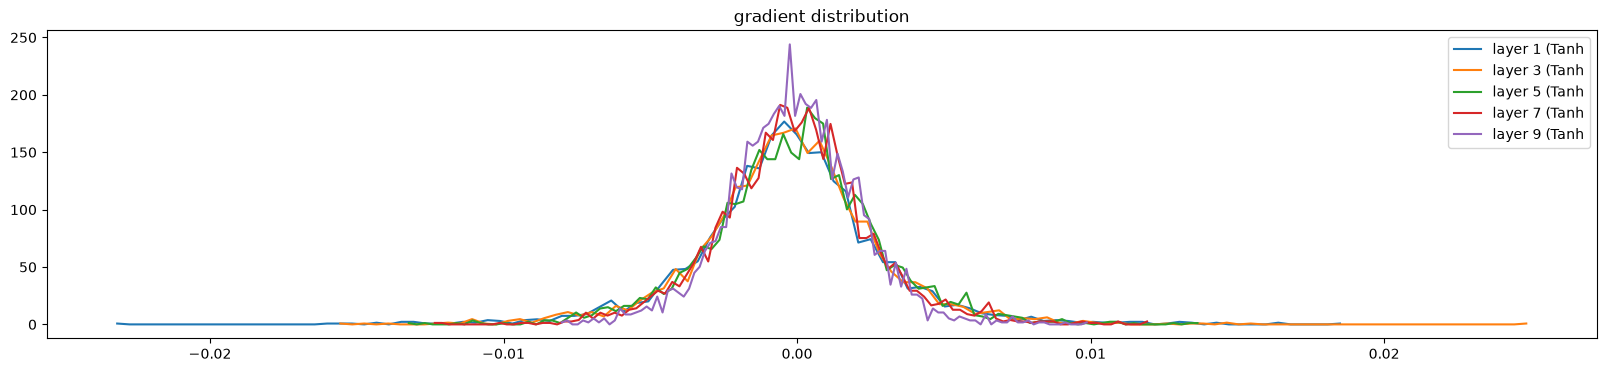

In [159]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    # print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution');

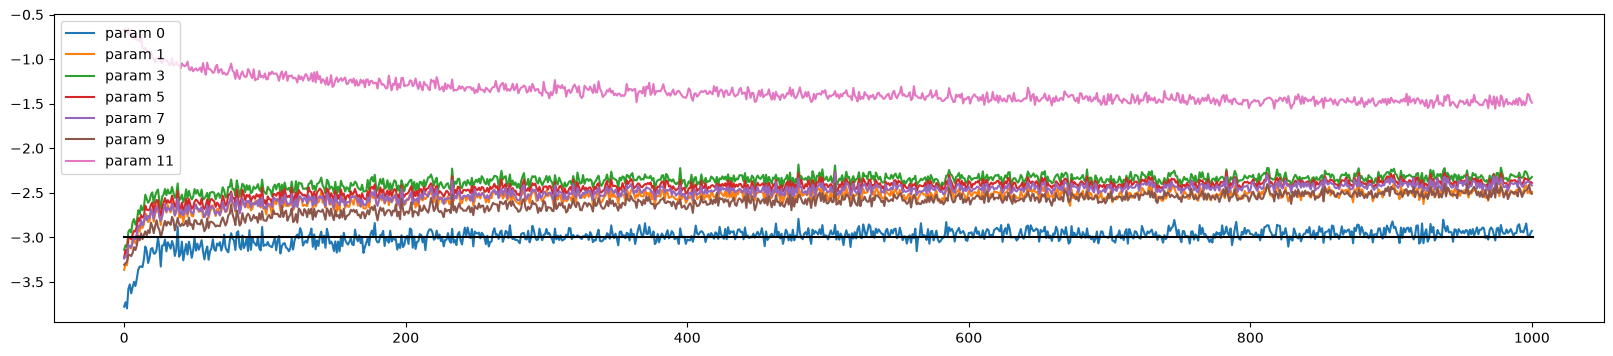

In [161]:
# here if values are below -3 it means your model is learning too slow (lr is too low) and viceversa

plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

In [162]:
# DONE; BONUS content below, not covered in video

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


interactive(children=(FloatSlider(value=0.0, description='x0', max=30.0, min=-30.0, step=0.5), Output()), _dom…

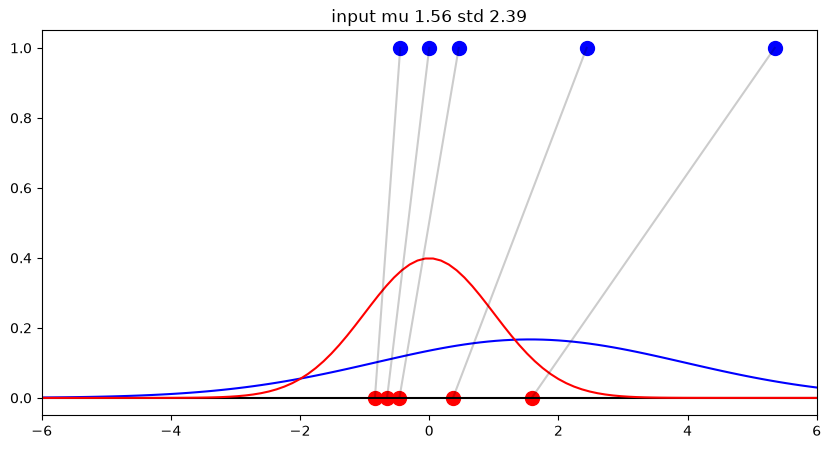

In [163]:
# BatchNorm forward pass as a widget

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
import scipy.stats as stats
import numpy as np

def normshow(x0):
  
  g = torch.Generator().manual_seed(2147483647+1)
  x = torch.randn(5, generator=g) * 5
  x[0] = x0                                      # override the 0th example with the slider
  mu = x.mean()
  sig = x.std()
  y = (x - mu)/sig

  plt.figure(figsize=(10, 5))
  # plot 0
  plt.plot([-6,6], [0,0], 'k')
  # plot the mean and std
  xx = np.linspace(-6, 6, 100)
  plt.plot(xx, stats.norm.pdf(xx, mu, sig), 'b')
  xx = np.linspace(-6, 6, 100)
  plt.plot(xx, stats.norm.pdf(xx, 0, 1), 'r')
  # plot little lines connecting input and output
  for i in range(len(x)):
    plt.plot([x[i],y[i]], [1, 0], 'k', alpha=0.2)
  # plot the input and output values
  plt.scatter(x.data, torch.ones_like(x).data, c='b', s=100)
  plt.scatter(y.data, torch.zeros_like(y).data, c='r', s=100)
  plt.xlim(-6, 6)
  # title
  plt.title('input mu %.2f std %.2f' % (mu, sig))

interact(normshow, x0=(-30,30,0.5));

In [164]:
# Linear: activation statistics of forward and backward pass

g = torch.Generator().manual_seed(2147483647)

a = torch.randn((1000,1), requires_grad=True, generator=g)          # a.grad = b.T @ c.grad
b = torch.randn((1000,1000), requires_grad=True, generator=g)       # b.grad = c.grad @ a.T
c = b @ a
loss = torch.randn(1000, generator=g) @ c
a.retain_grad()
b.retain_grad()
c.retain_grad()
loss.backward()
print('a std:', a.std().item())
print('b std:', b.std().item())
print('c std:', c.std().item())
print('-----')
print('c grad std:', c.grad.std().item())
print('a grad std:', a.grad.std().item())
print('b grad std:', b.grad.std().item())

a std: 0.9875972270965576
b std: 1.0006722211837769
c std: 31.01241683959961
-----
c grad std: 0.9782556295394897
a grad std: 30.8818302154541
b grad std: 0.9666601419448853


In [165]:
# Linear + BatchNorm: activation statistics of forward and backward pass

g = torch.Generator().manual_seed(2147483647)

n = 1000
# linear layer ---
inp = torch.randn(n, requires_grad=True, generator=g)
w = torch.randn((n, n), requires_grad=True, generator=g) # / n**0.5
x = w @ inp
# bn layer ---
xmean = x.mean()
xvar = x.var()
out = (x - xmean) / torch.sqrt(xvar + 1e-5)
# ----
loss = out @ torch.randn(n, generator=g)
inp.retain_grad()
x.retain_grad()
w.retain_grad()
out.retain_grad()
loss.backward()

print('inp std: ', inp.std().item())
print('w std: ', w.std().item())
print('x std: ', x.std().item())
print('out std: ', out.std().item())
print('------')
print('out grad std: ', out.grad.std().item())
print('x grad std: ', x.grad.std().item())
print('w grad std: ', w.grad.std().item())
print('inp grad std: ', inp.grad.std().item())

inp std:  0.9875972270965576
w std:  1.0006722211837769
x std:  31.01241683959961
out std:  1.0
------
out grad std:  0.9782556295394897
x grad std:  0.031543977558612823
w grad std:  0.031169468536973
inp grad std:  0.9953054189682007
